In [1]:
!pip install matplotlib seaborn pandas numpy pillow

In [2]:
import os
import json
import zipfile
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from google.colab import files

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
uploaded = files.upload()

Saving archive.zip to archive.zip


In [4]:
zip_name = list(uploaded.keys())[0]

extract_path = "/content/traffic_dataset"

with zipfile.ZipFile(zip_name, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

for root, dirs, files_list in os.walk(extract_path):
    print(root, ":", len(files_list), "files")

Dataset extracted successfully!
/content/traffic_dataset : 0 files
/content/traffic_dataset/traffic_detector_dataset : 2 files
/content/traffic_dataset/traffic_detector_dataset/train : 336 files
/content/traffic_dataset/traffic_detector_dataset/val : 144 files


In [5]:
json_files = glob.glob(
    extract_path + "/**/*.json",
    recursive=True
)

print("JSON annotation files found:")

for f in json_files:
    print(f)

JSON annotation files found:
/content/traffic_dataset/traffic_detector_dataset/train.json
/content/traffic_dataset/traffic_detector_dataset/val.json
/content/traffic_dataset/traffic_detector_dataset/train/trafficlight1.json
/content/traffic_dataset/traffic_detector_dataset/train/truck16.json
/content/traffic_dataset/traffic_detector_dataset/train/person7.json
/content/traffic_dataset/traffic_detector_dataset/train/moto12.json
/content/traffic_dataset/traffic_detector_dataset/train/person16.json
/content/traffic_dataset/traffic_detector_dataset/train/bus7.json
/content/traffic_dataset/traffic_detector_dataset/train/car16.json
/content/traffic_dataset/traffic_detector_dataset/train/person14.json
/content/traffic_dataset/traffic_detector_dataset/train/person17.json
/content/traffic_dataset/traffic_detector_dataset/train/bicycle8.json
/content/traffic_dataset/traffic_detector_dataset/train/truck11.json
/content/traffic_dataset/traffic_detector_dataset/train/bicycle19.json
/content/traffic_

In [6]:
annotation_file = next(
    (f for f in json_files if "annotation" in os.path.basename(f).lower()),
    json_files[0] if json_files else None
)

if annotation_file is None:
    raise FileNotFoundError("No JSON file found in the dataset!")

with open(annotation_file, "r") as f:
    coco = json.load(f)

print("COCO annotations loaded successfully!")
print("Images:", len(coco["images"]))
print("Categories:", len(coco["categories"]))
print("Annotations:", len(coco["annotations"]))

COCO annotations loaded successfully!
Images: 168
Categories: 8
Annotations: 272


In [7]:
categories = pd.DataFrame(coco["categories"])

print("Object Categories:")
display(categories)

Object Categories:


,supercategory,id,name
0,bicycle,0,bicycle
1,bus,1,bus
2,car,2,car
3,motorcycle,3,motorcycle
4,person,4,person
5,stop sign,5,stop sign
6,traffic light,6,traffic light
7,truck,7,truck


In [8]:
category_map = {
    item["id"]: item["name"]
    for item in coco["categories"]
}

annotations = pd.DataFrame(coco["annotations"])

annotations["category_name"] = annotations["category_id"].map(
    category_map
)

annotations["bbox_width"] = annotations["bbox"].apply(lambda x: x[2])
annotations["bbox_height"] = annotations["bbox"].apply(lambda x: x[3])
annotations["bbox_area"] = (
    annotations["bbox_width"] * annotations["bbox_height"]
)

print("Annotation data prepared!")
display(annotations.head())

Annotation data prepared!


,segmentation,iscrowd,area,image_id,bbox,category_id,id,category_name,bbox_width,bbox_height,bbox_area
0,"[[165.4074074074074, 277.16049382716045, 156.7...",0,43141.479957,0,"[66.0, 269.0, 353.0, 231.0]",0,1,bicycle,353.0,231.0,81543.0
1,"[[389.48148148148147, 324.0740740740741, 374.6...",0,45440.298735,1,"[357.0, 264.0, 237.0, 335.0]",0,2,bicycle,237.0,335.0,79395.0
2,"[[261.7037037037037, 364.1975308641975, 246.27...",0,64799.557994,2,"[230.0, 267.0, 314.0, 332.0]",0,3,bicycle,314.0,332.0,104248.0
3,"[[345.037037037037, 299.3827160493827, 278.987...",0,124387.399025,3,"[64.0, 296.0, 663.0, 303.0]",0,4,bicycle,663.0,303.0,200889.0
4,"[[287.6296296296296, 266.66666666666663, 270.3...",0,117103.455114,4,"[37.0, 266.0, 762.0, 333.0]",0,5,bicycle,762.0,333.0,253746.0


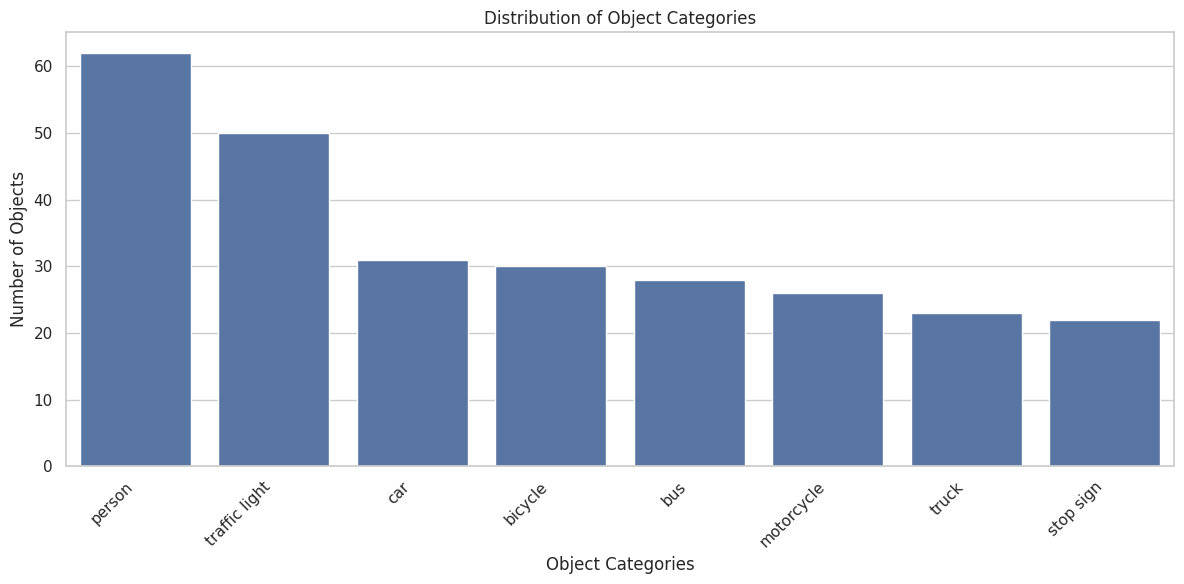

In [9]:
plt.figure(figsize=(12, 6))

category_counts = annotations["category_name"].value_counts()

sns.barplot(
    x=category_counts.index,
    y=category_counts.values
)

plt.title("Distribution of Object Categories")
plt.xlabel("Object Categories")
plt.ylabel("Number of Objects")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

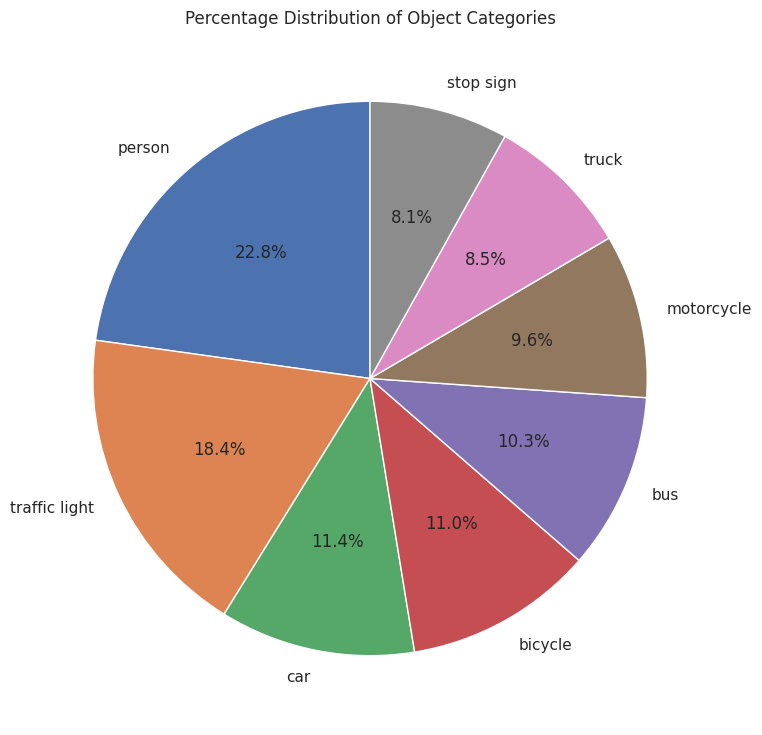

In [14]:
plt.figure(figsize=(9, 9))

category_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Percentage Distribution of Object Categories")
plt.ylabel("")

plt.show()

In [17]:

# FINAL DATASET SUMMARY

total_images = len(coco["images"])
total_annotations = len(coco["annotations"])
total_categories = len(coco["categories"])

print("=" * 45)
print("       SKILL 5 - DATASET SUMMARY")
print("=" * 45)

print("Total Images:", total_images)
print("Total Annotations:", total_annotations)
print("Total Object Categories:", total_categories)

print("\nOBJECT CATEGORY COUNTS:")

for category, count in category_counts.items():
    print(f"{category}: {count}")

print("\nMOST FREQUENT CATEGORY:",
      category_counts.idxmax())

print("LEAST FREQUENT CATEGORY:",
      category_counts.idxmin())

print("\nBar graph and pie chart generated successfully!")

print("=" * 45)


       SKILL 5 - DATASET SUMMARY
Total Images: 168
Total Annotations: 272
Total Object Categories: 8

OBJECT CATEGORY COUNTS:
person: 62
traffic light: 50
car: 31
bicycle: 30
bus: 28
motorcycle: 26
truck: 23
stop sign: 22

MOST FREQUENT CATEGORY: person
LEAST FREQUENT CATEGORY: stop sign

Bar graph and pie chart generated successfully!
